<a href="https://colab.research.google.com/github/laksamanaap/244107020021-machine-leaning-course-2026-/blob/main/JS08/JS08_TugasLab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
!pip install hdbscan

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import hdbscan

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [13]:
# Load  dataset Iris
iris = load_iris()

# Buat data frame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Tambahkan label
df['Target'] = iris.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [14]:
print("Jumlah data:", df.shape[0])
print("Jumlah fitur:", len(iris.feature_names))

print("\nDistribusi label asli:")
print(df['Target'].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum())

Jumlah data: 150
Jumlah fitur: 4

Distribusi label asli:
Target
0    50
1    50
2    50
Name: count, dtype: int64

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Target               0
dtype: int64


In [15]:
# Ambil fitur
X = df[iris.feature_names]

# Standarisasi Data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Ukuran data:", X_scaled.shape)

Ukuran data: (150, 4)


In [16]:
from sklearn.cluster import HDBSCAN

# model HDBSCAN
model = HDBSCAN(
    min_cluster_size=5,
    min_samples=3,
    cluster_selection_method='eom'
)

# Clustering
labels = model.fit_predict(X_scaled)

# Tambah hasil cluster
df['Cluster'] = labels

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target,Cluster
0,5.1,3.5,1.4,0.2,0,0
1,4.9,3.0,1.4,0.2,0,0
2,4.7,3.2,1.3,0.2,0,0
3,4.6,3.1,1.5,0.2,0,0
4,5.0,3.6,1.4,0.2,0,0


In [17]:
# Hitung jumlah cluster (belum termasuk noise)
n_clusters = len(set(labels) - {-1})

# Hitung jumlah noise
n_noise = list(labels).count(-1)

print("Jumlah cluster:", n_clusters)
print("Jumlah noise:", n_noise)

# Distribusi anggota cluster
print("\nDistribusi data:")
print(pd.Series(labels).value_counts().sort_index())

Jumlah cluster: 2
Jumlah noise: 0

Distribusi data:
0     50
1    100
Name: count, dtype: int64


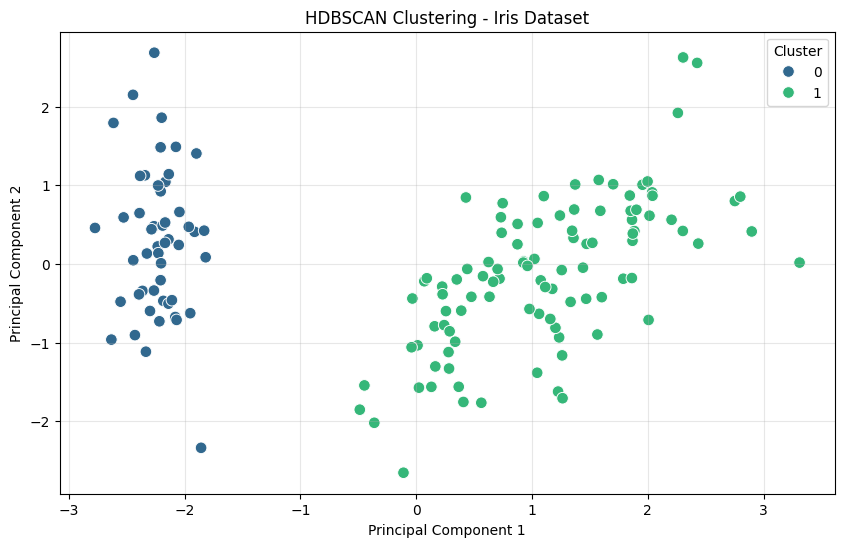

In [18]:
# Reduksi dimensi menggunakan PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# DF hasil PCA
df_pca = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

df_pca['Cluster'] = labels
df_pca['Target'] = df['Target']

# Visualisasi clustering
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_pca,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='viridis',
    s=70
)

plt.title('HDBSCAN Clustering - Iris Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)
plt.show()

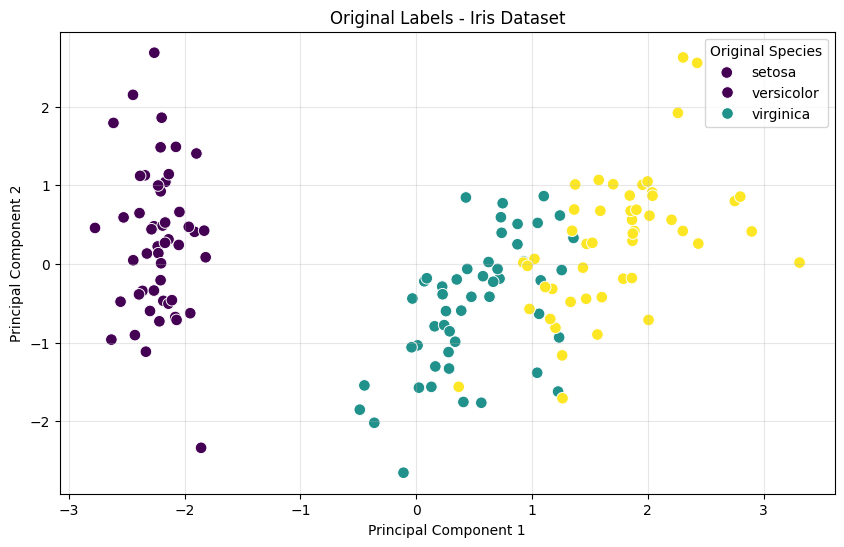

Adjusted Rand Index: 0.5681159420289855
HDBSCAN Cluster    0   1
Original Species        
0                 50   0
1                  0  50
2                  0  50


In [19]:
# Bandingkan hasil clustering dengan label asli
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_pca,
    x='PC1',
    y='PC2',
    hue='Target',
    palette='viridis',
    s=70
)

plt.title('Original Labels - Iris Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(
    title='Original Species',
    labels=iris.target_names
)
plt.grid(alpha=0.3)
plt.show()

# ARI untuk mengukur kesesuaian hasil clustering dengan hasil asli
ari_score = adjusted_rand_score(
    df['Target'],
    df['Cluster']
)

print("Adjusted Rand Index:", ari_score)

# Perbandingan kelompok
comparison = pd.crosstab(
    df['Target'],
    df['Cluster'],
    rownames=['Original Species'],
    colnames=['HDBSCAN Cluster']
)

print(comparison)

Diperoleh dua cluster dari total 150 data dengan jumlah noise sebanyak 0 data. Cluster 0 terdiri dari 50 data, sedangkan Cluster 1 terdiri dari 100 data

Visualisasi menggunakan PCA menunjukkan bahwa Iris Setosa berhasil dikelompokkan secara terpisah, sementara Iris Versicolor dan Iris Virginica berada dalam satu cluster. Hasil perbandingan menggunakan Adjusted Rand Index (ARI) menghasilkan nilai sebesar 0,5681. Nilai tersebut menunjukkan bahwa hasil clustering memiliki kesesuaian sebagian dengan label asli dataset, tetapi belum sepenuhnya mampu membedakan ketiga spesies bunga Iris

Dengan demikian, HDBSCAN mampu mengidentifikasi kelompok berdasarkan kepadatan data, meskipun hasil pengelompokannya tidak selalu sama dengan klasifikasi asli dataset